# 03 · Model experiments (MLflow)

Compares four algorithms with every run tracked in MLflow, then reviews the registered champion. **Start the tracking server first:**

```bash
uv run mlflow server --backend-store-uri sqlite:///mlflow.db --artifacts-destination ./mlartifacts --port 5000
```

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, mlflow, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from credit_risk import load_config, project_path
from credit_risk.ingestion import make_splits, sample_splits
from credit_risk.train import setup_mlflow, train_and_log, ALGORITHMS

sns.set_theme(style="whitegrid"); cfg = load_config()
print("Tracking URI:", setup_mlflow(cfg))
splits = make_splits(cfg)
sample = sample_splits(splits, 60_000, cfg)
print(f"Experiment sample: train {len(sample.train):,} | val {len(sample.val):,} | test {len(sample.test):,}")

Tracking URI: http://127.0.0.1:5000


Experiment sample: train 60,000 | val 15,000 | test 18,751


## 1. Algorithm comparison on a 60k sample

Each call to `train_and_log` creates a run with params, metrics, plots (ROC, calibration, PD distribution), the decile table, feature importance and the full model pipeline.

In [2]:
results = []
for algo in ALGORITHMS:
    r = train_and_log(algo, sample, run_name=f"nb03-{algo}", cfg=cfg)
    results.append({"model": algo, **{k: r[k] for k in ["val_roc_auc", "val_ks", "val_brier", "test_roc_auc", "fit_seconds"] if k in r},
                    "run_id": r["run_id"]})
cmp = pd.DataFrame(results).sort_values("val_roc_auc", ascending=False, ignore_index=True)
cmp

2026/11/23 04:28:29 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run nb03-logreg at: http://127.0.0.1:5000/#/experiments/1/runs/bcd8f62614d143519fe0c1855b3cccf9
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


2026/11/23 04:28:41 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run nb03-hgb at: http://127.0.0.1:5000/#/experiments/1/runs/c17d6566775c495480bb2aa0deee9385
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


2026/11/23 04:28:52 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run nb03-xgboost at: http://127.0.0.1:5000/#/experiments/1/runs/1c671ff3502a44a4b2629d104f97caf3
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


2026/11/23 04:29:05 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run nb03-lightgbm at: http://127.0.0.1:5000/#/experiments/1/runs/ab893ce8e2074f7dab3b0fdd9399b93a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


,model,val_roc_auc,val_ks,val_brier,test_roc_auc,run_id
0,lightgbm,0.754529,0.383866,0.068179,0.751959,ab893ce8e2074f7dab3b0fdd9399b93a
1,hgb,0.752253,0.377100,0.068193,0.751360,c17d6566775c495480bb2aa0deee9385
2,xgboost,0.752226,0.374610,0.068391,0.752150,1c671ff3502a44a4b2629d104f97caf3
3,logreg,0.745241,0.365883,0.068784,0.742782,bcd8f62614d143519fe0c1855b3cccf9


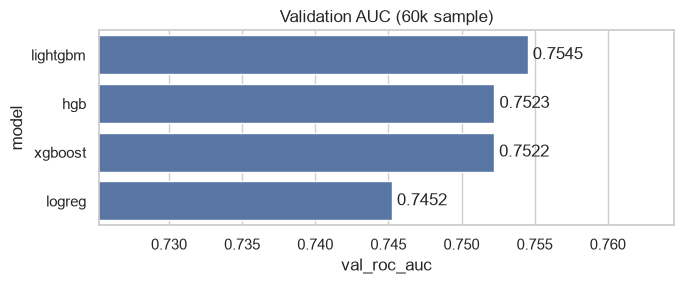

In [3]:
fig, ax = plt.subplots(figsize=(7, 3))
sns.barplot(cmp, x="val_roc_auc", y="model", ax=ax, color="#4c72b0")
ax.set_xlim(cmp.val_roc_auc.min() - 0.02, cmp.val_roc_auc.max() + 0.01); ax.set_title("Validation AUC (60k sample)")
for i, v in enumerate(cmp.val_roc_auc): ax.text(v, i, f" {v:.4f}", va="center")
plt.tight_layout(); plt.show()

Selection is based on **validation** metrics. The three gradient-boosting models are close to each other and all ahead of logistic regression, which is consistent with non-linear effects such as the non-monotonic repayment rate. With the full training set the gap widens (see the full-data runs below).

## 2. Querying the experiment

Everything logged is queryable, e.g. all finished non-validation runs ranked by validation AUC:

In [4]:
runs = mlflow.search_runs(experiment_names=[cfg["mlflow"]["experiment_name"]],
                          filter_string="attributes.status = 'FINISHED' and metrics.val_roc_auc > 0",
                          order_by=["metrics.val_roc_auc DESC"])
cols = ["tags.mlflow.runName", "params.model", "params.n_train", "metrics.val_roc_auc", "metrics.test_roc_auc", "metrics.test_ks", "metrics.test_brier"]
runs[[c for c in cols if c in runs]].head(10)

,tags.mlflow.runName,params.model,params.n_train,metrics.val_roc_auc,metrics.test_roc_auc,metrics.test_ks,metrics.test_brier
0,lightgbm,lightgbm,196806,0.763288,0.768515,0.399617,0.067047
1,nb03-lightgbm,lightgbm,60000,0.754529,0.751959,0.385536,0.068043
2,nb03-hgb,hgb,60000,0.752253,0.751360,0.378606,0.067949
3,nb03-xgboost,xgboost,60000,0.752226,0.752150,0.382274,0.068052
4,logreg,logreg,30000,0.746191,0.753150,0.380945,0.067947
5,nb03-logreg,logreg,60000,0.745241,0.742782,0.356837,0.068591


## 3. The registered champion

Full-data models are registered (`--register`), validated against the current champion on the hold-out test split, and promoted through the `@champion` alias (`credit_risk.evaluate --promote`). Promotion exports the champion to `artifacts/model` and `artifacts/metrics.json` for the API and dashboard.

In [5]:
from mlflow import MlflowClient
client = MlflowClient(); name = cfg["mlflow"]["registered_model_name"]
aliases = client.get_registered_model(name).aliases
pd.DataFrame([{"version": v.version, "aliases": ", ".join(a for a, ver in aliases.items() if ver == v.version),
               "validation_status": v.tags.get("validation_status"), "test_roc_auc": v.tags.get("test_roc_auc")}
              for v in client.search_model_versions(f"name='{name}'")]).sort_values("version")

,version,aliases,validation_status,test_roc_auc
1,1,previous_champion,passed,0.7449
0,2,"challenger, champion",passed,0.7685


In [6]:
meta = json.loads(project_path(cfg["artifacts"]["metrics_path"]).read_text())
print(f"Champion: {meta['model_name']} v{meta['version']} ({meta['algorithm']}, {meta['n_train']:,} training rows)")
pd.Series(meta["metrics"]).to_frame("test")

Champion: credit-risk-pd v2 (lightgbm, 196,806 training rows)


,test
roc_auc,0.768515
gini,0.537030
ks,0.399617
pr_auc,0.258979
brier,0.067047
log_loss,0.242704
observed_default_rate,0.080728
mean_predicted_pd,0.080037


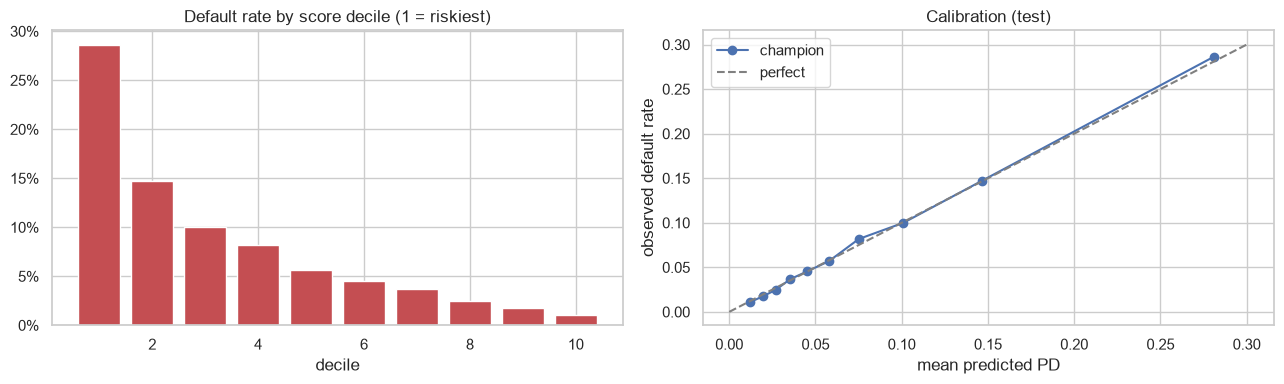

Top two deciles capture 54% of defaults.


In [7]:
dec = pd.DataFrame(meta["deciles"]); cal = meta["calibration"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(dec.decile, dec.default_rate, color="#c44e52"); axes[0].set(title="Default rate by score decile (1 = riskiest)", xlabel="decile")
axes[0].yaxis.set_major_formatter("{x:.0%}")
axes[1].plot(cal["mean_predicted"], cal["observed"], "o-", label="champion"); lim = max(cal["observed"]) * 1.05
axes[1].plot([0, lim], [0, lim], "--", c="grey", label="perfect"); axes[1].set(title="Calibration (test)", xlabel="mean predicted PD", ylabel="observed default rate"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"Top two deciles capture {dec.defaults.iloc[:2].sum() / dec.defaults.sum():.0%} of defaults.")

## Next steps

- Tune the leading algorithm on full data: `uv run python -m credit_risk.train --model lightgbm --tune --trials 40 --sample 80000`
- Register the best configuration on full data, then validate it: `uv run python -m credit_risk.evaluate`
- Look at segment performance and fairness (model-validator agent), and monitoring (dashboard page 5).